In [2]:
import polars as pl
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon
import matplotlib.pyplot as plt
#import from one up directory
import sys
sys.path.append("..")


In [ ]:
#load the filtered PO data/input_files/uk_foursquare_datefields_admin_categories_retailfilt.parquet

foursquare = pl.read_parquet("../../data/input_files/uk_foursquare_datefields_admin_categories_retailfilt.parquet")
# foursquare['fsq_category_labels']
#sort by fsq_category_labels
foursquare = foursquare.sort("fsq_category_labels")
#unique fsq_category_labels
unique_categories = foursquare.select(pl.col("fsq_category_labels").unique().sort()).to_series()

NameError: name 'pl' is not defined

NameError: name 'foursquare' is not defined

In [14]:
unique_categories = (
    foursquare
    .select(pl.col("fsq_category_labels").explode())  # convert list[str] -> str across rows
    .unique()
    .sort("fsq_category_labels")
    .to_series()
)


In [ ]:
unique_categories.to_csv("../../data/output_files/unique_fsq_category_labels.csv", index=False)

fsq_category_labels
str
"""Arts and Entertainment"""
"""Arts and Entertainment > Amuse…"
"""Arts and Entertainment > Amuse…"
"""Arts and Entertainment > Aquar…"
"""Arts and Entertainment > Arcad…"
…
"""Travel and Transportation > Tr…"
"""Travel and Transportation > Tr…"
"""Travel and Transportation > Tr…"


In [4]:

foursquare = pl.read_parquet('../../data/input_files/uk_foursquare_datefields_admin_categories.parquet')
# overture = pl.read_parquet('../data/input_files/poi_uk_overture_proc.parquet')  


In [5]:
#save version of foursquare with only cats and name
foursquare_cats = foursquare.select(['geometry','name', 'category_name', 'level1_category_name', 'level2_category_name', 'level3_category_name'])

In [7]:
#get unique level 1 categories
level1_categories = foursquare_cats.select(pl.col('level1_category_name').unique().sort()).to_series().to_list()
level1_categories

['Arts and Entertainment',
 'Business and Professional Services',
 'Community and Government',
 'Dining and Drinking',
 'Event',
 'Health and Medicine',
 'Landmarks and Outdoors',
 'Retail',
 'Sports and Recreation',
 'Travel and Transportation']

In [ ]:
#save version of foursquare with only cats and name
foursquare_cats = foursquare.select(['geometry','name', 'category_name', 'level1_category_name', 'level2_category_name', 'level3_category_name'])

foursquare_cats.write_parquet('../data/input_files/uk_foursquare_cats.parquet')

In [17]:
foursquare = foursquare.filter(
    (foursquare["level1_category_name"] == "Retail")
    | (foursquare["level1_category_name"] == "Dining and Drinking")
    | (foursquare["level1_category_name"] == "Arts and Entertainment")
    | (foursquare["level1_category_name"] == "Sports and Recreation")
    | (foursquare["level2_category_name"] == "Health and Beauty Service")  #buissness
    | (foursquare["level2_category_name"] == "Automotive Service")  #buissness
    # | (foursquare["level3_category_name"] == "ATM") #buisness, finanaical service
    | (foursquare["level4_category_name"] == "Bank") #buisness, finanaical service
    | (foursquare["level3_category_name"] == "Credit Union") #buisness, finanaical service
    | (foursquare["level3_category_name"] == "Real Estate Agency") #buisness,real estate serice
    | (foursquare["level3_category_name"] == "Law Office") 
    | (foursquare["level3_category_name"] == "Loans Agency") #buisness, finanaical service
    # | (foursquare["level3_category_name"] == "Insurance Agency") #buisness, finanaical service
    | (foursquare["level2_category_name"] == "Computer Repair Service") #buisness
    | (foursquare["level2_category_name"] == "Pet Service") #buisness
    | (foursquare["level2_category_name"] == "Photography Service") #buisness
    | (foursquare["level2_category_name"] == "Locksmith") #buisness
    | (foursquare["level2_category_name"] == "Funeral Home") #buisness
    | (foursquare["level3_category_name"] == "Coworking Space") #buisness, offce
    | (foursquare["level2_category_name"] == "Laundry Service") #buisness
    | (foursquare["level2_category_name"] == "Laundromat") #buisness
    #transsport
    | (foursquare["level2_category_name"] == "Fuel Station") #transsport
    | (foursquare["level2_category_name"] == "Travel Agency") #transsport
    | (foursquare["level2_category_name"] == "Tourist Information and Service") #transsport (covers tourist info shops and some travel agencies)
    #medical 
    | (foursquare["level3_category_name"] == "Doctors Office") #most gps
    | (foursquare["level2_category_name"] == "Dentist") #dentists
    | (foursquare["level2_category_name"] == "Veterinarian") #vets
    | (foursquare["level2_category_name"] == "Physical Therapy Clinic") #physio
    #community
    | (foursquare["level3_category_name"] == "Post Office") #community
    | (foursquare["level2_category_name"] == "Library") #community
    | (foursquare["level2_category_name"] == "Community Center") #community
    | (foursquare["level2_category_name"] == "Social Club") #community
)



In [19]:
#save version of foursquare with only cats and name
foursquare_cats = foursquare.select(['geometry','name', 'category_name', 'level1_category_name', 'level2_category_name', 'level3_category_name'])
foursquare_cats

geometry,name,category_name,level1_category_name,level2_category_name,level3_category_name
binary,str,str,str,str,str
"b""\x01\x01\x00\x00\x00\x15_\x0b\x94mW\x0fAy\xd5\x0d\xd4\xc9q$A""","""Bellcraig community centre""","""Community Center""","""Community and Government""","""Community Center""",null
"b""\x01\x01\x00\x00\x00NO\x1du\x1a\x0f\x0fAI\x8d\xed:\xafn$A""","""Smart a B C""","""Automotive Repair Shop""","""Business and Professional Serv…","""Automotive Service""","""Automotive Repair Shop"""
"b""\x01\x01\x00\x00\x00\xd3`\xfc7~\x8c\x0fA\x91\xca\x9b\x05v?$A""","""DJ's""","""Bar""","""Dining and Drinking""","""Bar""",null
"b""\x01\x01\x00\x00\x00\xb2\xc6\x08\x94\x82\x03\x10A\x9e|\x83\xc2\xf6F$A""","""The Forge Shopping Centre""","""Shopping Mall""","""Retail""","""Shopping Mall""",null
"b""\x01\x01\x00\x00\x00\xf4\xf9\xd0\xc2\xe0\xa0\x0fA\x87w2\xf3\xb9`$A""","""Desa Ink""","""Tattoo Parlor""","""Business and Professional Serv…","""Health and Beauty Service""","""Tattoo Parlor"""
…,…,…,…,…,…
"b""\x01\x01\x00\x00\x00\xa8>\x03%\x82\x1d\xf6@8t\x0fS\xa6\xc2\xc4@""","""Cut Loose""","""Hair Salon""","""Business and Professional Serv…","""Health and Beauty Service""","""Hair Salon"""
"b""\x01\x01\x00\x00\x00@[\xdd\x1b\x20]\xf6@@\xa2\xd7y\xba\x92\xcf@""","""Fay Page""","""Jewelry Store""","""Retail""","""Fashion Retail""","""Jewelry Store"""
"b""\x01\x01\x00\x00\x00\x8c\x0b\x8d\xb2`\x16\xf6@\x20\x96\xee0\xbc^\xc4@""","""St Mary's Library""","""Library""","""Community and Government""","""Library""",null


In [13]:
foursquare_notinc = foursquare.filter(~(
    (foursquare["level1_category_name"] == "Retail")
    | (foursquare["level1_category_name"] == "Dining and Drinking")
    | (foursquare["level1_category_name"] == "Arts and Entertainment")
    | (foursquare["level1_category_name"] == "Sports and Recreation")
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Health and Beauty Service")  #buissness
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Automotive Service")  #buissness
    # | (foursquare["level3_category_name"] == "ATM") #buisness, finanaical service
    | (foursquare["level4_category_name"].fill_null("Unknown") == "Bank") #buisness, finanaical service
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Credit Union") #buisness, finanaical service
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Real Estate Agency") #buisness,real estate serice
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Law Office") 
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Loans Agency") #buisness, finanaical service
    # | (foursquare["level3_category_name"] == "Insurance Agency") #buisness, finanaical service
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Computer Repair Service") #buisness
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Pet Service") #buisness
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Photography Service") #buisness
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Locksmith") #buisness
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Funeral Home") #buisness
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Coworking Space") #buisness, offce
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Laundry Service") #buisness
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Laundromat") #buisness
    #transsport
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Fuel Station") #transsport
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Travel Agency") #transsport
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Tourist Information and Service") #transsport (covers tourist info shops and some travel agencies)
    #medical 
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Doctor's Office") #most gps
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Dentist") #dentists
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Veterinarian") #vets
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Physical Therapy Clinic") #physio
    #community
    | (foursquare["level3_category_name"].fill_null("Unknown") == "Post Office") #community
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Library") #community
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Community Center") #community
    | (foursquare["level2_category_name"].fill_null("Unknown") == "Social Club") #community
)
)


foursquare_notincbank = foursquare_notinc.select(['geometry','name', 'category_name', 'level1_category_name', 'level2_category_name', 'level3_category_name'])

foursquare_notincbank.write_parquet('../data/input_files/uk_foursquare_notincbank.parquet')

In [ ]:
(foursquare["level3_category_name"] == "Bank") #buisness, finanaical service

level3_category_name
bool
null
false
null
null
null
…
null
null
null


In [12]:
pl.Config(tbl_rows=1000)
#more width
pl.Config.set_tbl_width_chars(10000)
print(foursquare['level1_category_name'].value_counts().sort(by="count",descending=True))

df =foursquare['level1_category_name'].value_counts().sort(by="count",descending=True)
df.write_csv('foursquare_categories.csv')


shape: (10, 2)
┌─────────────────────────────────┬─────────┐
│ level1_category_name            ┆ count   │
│ ---                             ┆ ---     │
│ str                             ┆ u32     │
╞═════════════════════════════════╪═════════╡
│ Business and Professional Serv… ┆ 1661855 │
│ Retail                          ┆ 932741  │
│ Dining and Drinking             ┆ 538708  │
│ Community and Government        ┆ 353367  │
│ Travel and Transportation       ┆ 286370  │
│ Health and Medicine             ┆ 195235  │
│ Landmarks and Outdoors          ┆ 177847  │
│ Sports and Recreation           ┆ 90958   │
│ Arts and Entertainment          ┆ 82770   │
│ Event                           ┆ 9717    │
└─────────────────────────────────┴─────────┘


In [9]:
#Buisnesses and Professional Services

print(foursquare.filter(foursquare['level1_category_name'] == 'Business and Professional Services')['level2_category_name'].value_counts().sort(by="count",descending=True))

shape: (104, 2)
┌─────────────────────────────────┬────────┐
│ level2_category_name            ┆ count  │
│ ---                             ┆ ---    │
│ str                             ┆ u32    │
╞═════════════════════════════════╪════════╡
│ Home Improvement Service        ┆ 331408 │
│ Health and Beauty Service       ┆ 145556 │
│ Automotive Service              ┆ 116041 │
│ null                            ┆ 114148 │
│ Financial Service               ┆ 106195 │
│ Office                          ┆ 96237  │
│ Real Estate Service             ┆ 92197  │
│ Legal Service                   ┆ 55138  │
│ Advertising Agency              ┆ 45119  │
│ Agriculture and Forestry Servi… ┆ 41288  │
│ Computer Repair Service         ┆ 31600  │
│ Engineer                        ┆ 27111  │
│ Employment Agency               ┆ 23884  │
│ Business Service                ┆ 21084  │
│ Shipping, Freight, and Materia… ┆ 20877  │
│ Technology Business             ┆ 20409  │
│ Photography Service             ┆ 192

In [10]:
print("retail")
print(foursquare.filter(foursquare["level1_category_name"]=="Retail")['level2_category_name'].value_counts().sort(by="count",descending=True))

retail
shape: (76, 2)
┌─────────────────────────────────┬────────┐
│ level2_category_name            ┆ count  │
│ ---                             ┆ ---    │
│ str                             ┆ u32    │
╞═════════════════════════════════╪════════╡
│ Construction Supplies Store     ┆ 131086 │
│ Fashion Retail                  ┆ 122944 │
│ Food and Beverage Retail        ┆ 106061 │
│ null                            ┆ 75728  │
│ Furniture and Home Store        ┆ 60134  │
│ Automotive Retail               ┆ 46974  │
│ Convenience Store               ┆ 42225  │
│ Computers and Electronics Reta… ┆ 31402  │
│ Print Store                     ┆ 25073  │
│ Sporting Goods Retail           ┆ 20080  │
│ Gift Store                      ┆ 18651  │
│ Pet Supplies Store              ┆ 18527  │
│ Miscellaneous Store             ┆ 17167  │
│ Hardware Store                  ┆ 16881  │
│ Flower Store                    ┆ 14354  │
│ Garden Center                   ┆ 13110  │
│ Pharmacy                       

In [9]:
print("Dining and Drinking")

print(foursquare.filter(foursquare["level1_category_name"]=="Dining and Drinking")['level2_category_name'].value_counts().sort(by="count",descending=True))

Dining and Drinking
shape: (24, 2)
┌─────────────────────────────┬────────┐
│ level2_category_name        ┆ count  │
│ ---                         ┆ ---    │
│ str                         ┆ u32    │
╞═════════════════════════════╪════════╡
│ Restaurant                  ┆ 278182 │
│ Bar                         ┆ 109312 │
│ Cafe, Coffee, and Tea House ┆ 90074  │
│ Bakery                      ┆ 23190  │
│ Dessert Shop                ┆ 10402  │
│ Breakfast Spot              ┆ 5238   │
│ Brewery                     ┆ 4409   │
│ Snack Place                 ┆ 4148   │
│ Food Truck                  ┆ 3628   │
│ null                        ┆ 3419   │
│ Juice Bar                   ┆ 1373   │
│ Food Court                  ┆ 816    │
│ Food Stand                  ┆ 784    │
│ Distillery                  ┆ 680    │
│ Cafeteria                   ┆ 635    │
│ Donut Shop                  ┆ 626    │
│ Bagel Shop                  ┆ 503    │
│ Winery                      ┆ 390    │
│ Creperie            

In [10]:
print("Arts and Entertainment")
print(foursquare.filter(foursquare['level1_category_name'] == "Arts and Entertainment")['level2_category_name'].value_counts().sort(by="count",descending=True))

Arts and Entertainment
shape: (42, 2)
┌────────────────────────┬───────┐
│ level2_category_name   ┆ count │
│ ---                    ┆ ---   │
│ str                    ┆ u32   │
╞════════════════════════╪═══════╡
│ null                   ┆ 19270 │
│ Performing Arts Venue  ┆ 15374 │
│ Art Gallery            ┆ 10534 │
│ Night Club             ┆ 7798  │
│ Museum                 ┆ 4705  │
│ Amusement Park         ┆ 3211  │
│ Movie Theater          ┆ 2913  │
│ Stadium                ┆ 2097  │
│ Public Art             ┆ 1904  │
│ Casino                 ┆ 1509  │
│ Arcade                 ┆ 1399  │
│ Bowling Alley          ┆ 1062  │
│ Pool Hall              ┆ 1022  │
│ Exhibit                ┆ 994   │
│ Strip Club             ┆ 988   │
│ Internet Cafe          ┆ 961   │
│ Zoo                    ┆ 891   │
│ Comedy Club            ┆ 887   │
│ Aquarium               ┆ 804   │
│ Psychic and Astrologer ┆ 566   │
│ Bingo Center           ┆ 566   │
│ Gaming Cafe            ┆ 444   │
│ Fair           

In [11]:
#Sports and Recreation
print("Sports and Recreation")
print(foursquare.filter(foursquare['level1_category_name'] == "Sports and Recreation")['level2_category_name'].value_counts().sort(by="count",descending=True))

Sports and Recreation
shape: (32, 2)
┌──────────────────────┬───────┐
│ level2_category_name ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Gym and Studio       ┆ 33111 │
│ Sports Club          ┆ 11848 │
│ null                 ┆ 10908 │
│ Golf                 ┆ 5030  │
│ Martial Arts Dojo    ┆ 5026  │
│ Soccer               ┆ 3711  │
│ Water Sports         ┆ 3260  │
│ Personal Trainer     ┆ 2288  │
│ Recreation Center    ┆ 2217  │
│ Racquet Sports       ┆ 1834  │
│ Cricket Ground       ┆ 1719  │
│ Equestrian Facility  ┆ 1461  │
│ Race Track           ┆ 1169  │
│ Indoor Play Area     ┆ 1102  │
│ Skating              ┆ 1014  │
│ Rugby                ┆ 879   │
│ Gun Range            ┆ 836   │
│ Paintball Field      ┆ 827   │
│ Running and Track    ┆ 568   │
│ Bowling Green        ┆ 444   │
│ Basketball           ┆ 313   │
│ Snow Sports          ┆ 271   │
│ Fishing Area         ┆ 263   │
│ Hockey               ┆ 255   │
│ Gymn

In [13]:
#events
print("Events")
print(foursquare.filter(foursquare['level1_category_name'] == "Event")['level2_category_name'].value_counts().sort(by="count",descending=True))

Events
shape: (7, 2)
┌──────────────────────┬───────┐
│ level2_category_name ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Entertainment Event  ┆ 4271  │
│ Other Event          ┆ 2698  │
│ Marketplace          ┆ 1192  │
│ Conference           ┆ 1028  │
│ Convention           ┆ 398   │
│ null                 ┆ 123   │
│ Line                 ┆ 7     │
└──────────────────────┴───────┘


In [15]:
#Travel and Transport
#table width
pl.Config.set_tbl_width_chars(10000)
print("Travel and Transport")
print(foursquare.filter(foursquare['level1_category_name'] == "Travel and Transportation")['level2_category_name'].value_counts().sort(by="count",descending=True))

Travel and Transport
shape: (29, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ Lodging                         ┆ 83285 │
│ Transport Hub                   ┆ 67800 │
│ Road                            ┆ 29523 │
│ Transportation Service          ┆ 26783 │
│ Fuel Station                    ┆ 18417 │
│ Travel Agency                   ┆ 15381 │
│ Parking                         ┆ 13343 │
│ null                            ┆ 10300 │
│ Tourist Information and Servic… ┆ 5173  │
│ Platform                        ┆ 3550  │
│ Train                           ┆ 3482  │
│ Moving Target                   ┆ 1667  │
│ RV Park                         ┆ 1580  │
│ Boat or Ferry                   ┆ 1443  │
│ Rest Area                       ┆ 976   │
│ Bike Rental                     ┆ 827   │
│ Electric Vehicle Charging Stat… ┆ 814 

In [19]:
#Health and Medicine
print("Health and Medicine")
print(foursquare.filter(foursquare['level1_category_name'] == "Health and Medicine")['level2_category_name'].value_counts().sort(by="count",descending=True))

Health and Medicine
shape: (30, 2)
┌───────────────────────────────┬───────┐
│ level2_category_name          ┆ count │
│ ---                           ┆ ---   │
│ str                           ┆ u32   │
╞═══════════════════════════════╪═══════╡
│ Physician                     ┆ 33773 │
│ Medical Center                ┆ 24631 │
│ Dentist                       ┆ 24420 │
│ Alternative Medicine Clinic   ┆ 17500 │
│ Nursing Home                  ┆ 15686 │
│ Hospital                      ┆ 8527  │
│ Mental Health Service         ┆ 8369  │
│ Veterinarian                  ┆ 7671  │
│ Healthcare Clinic             ┆ 6955  │
│ Physical Therapy Clinic       ┆ 6907  │
│ Optometrist                   ┆ 6594  │
│ null                          ┆ 6001  │
│ Assisted Living Service       ┆ 5772  │
│ Home Health Care Service      ┆ 5407  │
│ Podiatrist                    ┆ 4040  │
│ Nutritionist                  ┆ 2771  │
│ Chiropractor                  ┆ 2719  │
│ Acupuncture Clinic            ┆ 2715  │

In [20]:
#Physician
print("Physician")
print(foursquare.filter(foursquare['level2_category_name'] == "Physician")['level3_category_name'].value_counts().sort(by="count",descending=True))

Physician
shape: (23, 2)
┌─────────────────────────────────┬───────┐
│ level3_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ null                            ┆ 20338 │
│ Doctor's Office                 ┆ 11596 │
│ Plastic Surgeon                 ┆ 805   │
│ General Surgeon                 ┆ 477   │
│ Dermatologist                   ┆ 332   │
│ Obstetrician Gynecologist (Ob-… ┆ 72    │
│ Family Medicine Doctor          ┆ 42    │
│ Ophthalmologist                 ┆ 23    │
│ Psychiatrist                    ┆ 18    │
│ Cardiologist                    ┆ 17    │
│ Ear, Nose and Throat Doctor     ┆ 13    │
│ Orthopedic Surgeon              ┆ 8     │
│ Oral Surgeon                    ┆ 7     │
│ Internal Medicine Doctor        ┆ 5     │
│ Pathologist                     ┆ 4     │
│ Gastroenterologist              ┆ 3     │
│ Pediatrician                    ┆ 3     │
│ Radio

In [21]:
#Community and Government
print("Community and Government")
print(foursquare.filter(foursquare['level1_category_name'] == "Community and Government")['level2_category_name'].value_counts().sort(by="count",descending=True))

Community and Government
shape: (32, 2)
┌────────────────────────────┬────────┐
│ level2_category_name       ┆ count  │
│ ---                        ┆ ---    │
│ str                        ┆ u32    │
╞════════════════════════════╪════════╡
│ Education                  ┆ 166435 │
│ Government Building        ┆ 40948  │
│ Spiritual Center           ┆ 38179  │
│ Organization               ┆ 37739  │
│ Residential Building       ┆ 15877  │
│ Assisted Living            ┆ 8484   │
│ Community Center           ┆ 8278   │
│ Social Club                ┆ 7089   │
│ Library                    ┆ 6321   │
│ Housing Development        ┆ 5239   │
│ null                       ┆ 4455   │
│ Public and Social Service  ┆ 4284   │
│ Cemetery                   ┆ 2622   │
│ Disabled Persons Service   ┆ 2419   │
│ Animal Shelter             ┆ 1888   │
│ Town Hall                  ┆ 560    │
│ Trailer Park               ┆ 488    │
│ Polling Place              ┆ 474    │
│ Cultural Center            ┆ 272    │


In [22]:
#Government Building
print("Government Building")
print(foursquare.filter(foursquare['level2_category_name'] == "Government Building")['level3_category_name'].value_counts().sort(by="count",descending=True))

Government Building
shape: (9, 2)
┌─────────────────────────────────┬───────┐
│ level3_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ Post Office                     ┆ 20767 │
│ null                            ┆ 7626  │
│ Law Enforcement and Public Saf… ┆ 5780  │
│ Government Department           ┆ 2703  │
│ Military                        ┆ 1488  │
│ Courthouse                      ┆ 1126  │
│ City Hall                       ┆ 769   │
│ Embassy or Consulate            ┆ 588   │
│ Capitol Building                ┆ 101   │
└─────────────────────────────────┴───────┘


In [18]:
foursquare.filter(foursquare['level2_category_name'] == "Tourist Information and Service")

fsq_place_id,name,lat,lng,address,locality,region,postcode,admin_region,post_town,po_box,country,date_created,date_refreshed,date_closed,tel,website,email,facebook_id,instagram,twitter,fsq_category_ids,fsq_category_labels,dt_x,geometry,h3_01,h3_02,h3_03,h3_04,h3_05,h3_06,h3_07,h3_08,h3_09,easting,northing,LAD22CD,LAD22NM,OA21CD,LSOA21CD,LSOA21NM,MSOA21CD,MSOA21NM,DZ11CD,DZ11NM,DZ2021_cd,DZ2021_nm,SDZ2021_cd,SDZ2021_nm,DEA2014_cd,DEA2014_nm,LGD2014_cd,LGD2014_nm,num_categories,category_id,category_level,category_name,category_label,level1_category_id,level1_category_name,level2_category_id,level2_category_name,level3_category_id,level3_category_name,level4_category_id,level4_category_name,level5_category_id,level5_category_name,level6_category_id,level6_category_name,dt_y
str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,list[str],str,binary,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,i32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,datetime[μs]
"""43e4148dc3694c98767476c6""","""About Scotland""",55.882071,-4.322698,"""32 Randolph Gate""","""Glasgow""",null,"""G11 7DE""","""Scotland""","""Glasgow""",null,"""GB""","""2017-06-30""","""2024-10-08""",null,"""0808 225 0224""","""http://www.aboutscotland.net""",null,null,null,null,"""56aa371be4b08b9a8d573520""","[""Travel and Transportation > Tourist Information and Service > Tour Provider""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xe8Wm\x86\xb3\x1a\x0fAr\x9b\xcd\x84\xc5a$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909ac7ffffff""","""871909ac6ffffff""","""881909ac6dfffff""","""891909ac6c7ffff""",254806.440638,667874.759381,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010416""","""Broomhill - 02""",null,null,null,null,null,null,null,null,1,"""56aa371be4b08b9a8d573520""",3,"""Tour Provider""","""Travel and Transportation > To…","""4d4b7105d754a06379d81259""","""Travel and Transportation""","""4f4530164b9074f6e4fb00ff""","""Tourist Information and Servic…","""56aa371be4b08b9a8d573520""","""Tour Provider""",null,null,null,null,null,null,2024-11-19 00:00:00
"""537507aa712b43e2fd988bdc""","""Scot Trek""",55.872788,-4.298072,"""Lawrence St""","""Glasgow""","""Lanarkshire""","""G11 5HH""","""Scotland""","""Glasgow""",null,"""GB""","""2010-05-20""","""2024-10-09""",null,"""0141 334 9232""","""http://www.scot-trek.co.uk""",null,null,null,null,"""56aa371be4b08b9a8d573520""","[""Travel and Transportation > Tourist Information and Service > Tour Provider""]","""2024-11-19""","b""\x01\x01\x00\x00\x00^\xbf\xd4>\xc2I\x0fA\xf8\x8e\xe6\xfcLY$A""","""81197ffffffffff""","""82190ffffffffff""","""831909fffffffff""","""841909bffffffff""","""851909affffffff""","""861909ac7ffffff""","""871909ac4ffffff""","""881909ac47fffff""","""891909ac46bffff""",256312.280679,666790.493947,"""S12000049""","""Glasgow City""",null,null,null,null,null,"""S01010384""","""Hillhead - 04""",null,null,null,null,null,null,null,null,1,"""56aa371be4b08b9a8d573520""",3,"""Tour Provider""","""Travel and Transportation > To…","""4d4b7105d754a06379d81259""","""Travel and Transportation""","""4f4530164b9074f6e4fb00ff""","""Tourist Information and Servic…","""56aa371be4b08b9a8d573520""","""Tour Provider""",null,null,null,null,null,null,2024-11-19 00:00:00
"""4c99f73e553cef3b6f96d077""","""Greater Glasgow & Clyde Valley…",55.860631,-4.250804,"""11 George Square""","""Glasgow""","""Lanarkshire""","""G2 1DY""","""Scotland""",null,null,"""GB""","""2010-09-22""","""2024-10-09""",null,"""0141 204 4400""","""http://www.seeglasgow.com""","""tourismglasgow@ggcvtb.org.uk""",1.3884e14,null,null,"""4f4530164b9074f6e4fb00ff""","[""Travel and Transportation > Tourist Information and Service""]","""2024-11-19""","b""\x01\x01\x00\x00\x00\xca\xda`k\xc9\xa4\x0fA\xc0\x9e\xfa\x1c\xf9M$A""","""81197ffffffffff""","""82190ffffffffff""","""8

In [10]:
#overture categories
print("Overture")
print(overture['level1_category_name'].value_counts().sort(by="count",descending=True))

Overture
shape: (23, 2)
┌─────────────────────────────────┬────────┐
│ level1_category_name            ┆ count  │
│ ---                             ┆ ---    │
│ str                             ┆ u32    │
╞═════════════════════════════════╪════════╡
│ retail                          ┆ 425049 │
│ null                            ┆ 315726 │
│ professional_services           ┆ 291325 │
│ eat_and_drink                   ┆ 207919 │
│ home_service                    ┆ 149000 │
│ beauty_and_spa                  ┆ 146950 │
│ business_to_business            ┆ 112595 │
│ health_and_medical              ┆ 103673 │
│ automotive                      ┆ 97987  │
│ active_life                     ┆ 96064  │
│ public_service_and_government   ┆ 91888  │
│ education                       ┆ 89576  │
│ accommodation                   ┆ 62314  │
│ travel                          ┆ 52707  │
│ real_estate                     ┆ 49816  │
│ financial_service               ┆ 49000  │
│ arts_and_entertainment       

In [9]:
#retail
print("Retail")
print(overture.filter(overture['level1_category_name'] == "retail")['level2_category_name'].value_counts().sort(by="count",descending=True))

Retail
shape: (22, 2)
┌─────────────────────────────┬────────┐
│ level2_category_name        ┆ count  │
│ ---                         ┆ ---    │
│ str                         ┆ u32    │
╞═════════════════════════════╪════════╡
│ shopping                    ┆ 334146 │
│ food                        ┆ 52567  │
│ pharmacy                    ┆ 11322  │
│ null                        ┆ 10917  │
│ carpet_store                ┆ 8383   │
│ party_supply                ┆ 3094   │
│ auto_parts_and_supply_store ┆ 1352   │
│ tire_shop                   ┆ 991    │
│ beverage_store              ┆ 595    │
│ distillery                  ┆ 582    │
│ flooring_store              ┆ 562    │
│ health_market               ┆ 237    │
│ drugstore                   ┆ 120    │
│ boat_parts_and_supply_store ┆ 68     │
│ meat_shop                   ┆ 44     │
│ seafood_market              ┆ 20     │
│ herb_and_spice_shop         ┆ 17     │
│ honey_farm_shop             ┆ 13     │
│ water_store                 ┆ 10 

In [13]:

print("Eat and Drink")
print(overture.filter(overture['level1_category_name'] == "eat_and_drink")['level2_category_name'].value_counts().sort(by="count",descending=True))

Eat and Drink
shape: (4, 2)
┌──────────────────────┬────────┐
│ level2_category_name ┆ count  │
│ ---                  ┆ ---    │
│ str                  ┆ u32    │
╞══════════════════════╪════════╡
│ restaurant           ┆ 107872 │
│ bar                  ┆ 55697  │
│ cafe                 ┆ 39888  │
│ null                 ┆ 4462   │
└──────────────────────┴────────┘


In [23]:
print("beauty_and_spa")
print(overture.filter(overture['level1_category_name'] == "beauty_and_spa")['level2_category_name'].value_counts().sort(by="count",descending=True))

beauty_and_spa
shape: (26, 2)
┌──────────────────────┬───────┐
│ level2_category_name ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ null                 ┆ 80104 │
│ beauty_salon         ┆ 31717 │
│ barber               ┆ 7513  │
│ tattoo_and_piercing  ┆ 6710  │
│ hair_salon           ┆ 5383  │
│ spas                 ┆ 3550  │
│ nail_salon           ┆ 2681  │
│ tanning_salon        ┆ 2234  │
│ hair_removal         ┆ 1839  │
│ makeup_artist        ┆ 1288  │
│ skin_care            ┆ 1269  │
│ massage              ┆ 1121  │
│ hair_extensions      ┆ 389   │
│ aromatherapy         ┆ 294   │
│ hair_replacement     ┆ 228   │
│ teeth_whitening      ┆ 169   │
│ health_spa           ┆ 117   │
│ image_consultant     ┆ 107   │
│ hair_loss_center     ┆ 75    │
│ eyelash_service      ┆ 64    │
│ permanent_makeup     ┆ 58    │
│ foot_care            ┆ 24    │
│ eyebrow_service      ┆ 10    │
│ public_bath_houses   ┆ 3     │
│ onsen      

In [21]:
print("arts_and_entertainment")
print(overture.filter(overture['level1_category_name'] == "arts_and_entertainment")['level2_category_name'].value_counts().sort(by="count",descending=True))

arts_and_entertainment
shape: (45, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ null                            ┆ 7799  │
│ farm                            ┆ 5698  │
│ music_venue                     ┆ 3899  │
│ theaters_and_performance_venue… ┆ 3590  │
│ betting_center                  ┆ 3457  │
│ dance_club                      ┆ 3004  │
│ cinema                          ┆ 2945  │
│ stadium_arena                   ┆ 2895  │
│ topic_concert_venue             ┆ 2645  │
│ casino                          ┆ 2015  │
│ performing_arts                 ┆ 1340  │
│ supernatural_reading            ┆ 1074  │
│ festival                        ┆ 1002  │
│ comedy_club                     ┆ 795   │
│ escape_rooms                    ┆ 467   │
│ choir                           ┆ 464   │
│ arcade                          ┆ 34

In [26]:

print("automotive")
print(overture.filter(overture['level1_category_name'] == "automotive")['level2_category_name'].value_counts().sort(by="count",descending=True))

automotive
shape: (18, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ automotive_repair               ┆ 25522 │
│ automotive_services_and_repair  ┆ 23151 │
│ automotive_dealer               ┆ 18993 │
│ null                            ┆ 12890 │
│ gas_station                     ┆ 6693  │
│ automotive_parts_and_accessori… ┆ 4185  │
│ electric_vehicle_charging_stat… ┆ 2572  │
│ auto_company                    ┆ 2345  │
│ boat_service_and_repair         ┆ 823   │
│ boat_dealer                     ┆ 255   │
│ boat_parts_and_accessories      ┆ 211   │
│ automobile_leasing              ┆ 184   │
│ motorcycle_manufacturer         ┆ 47    │
│ car_buyer                       ┆ 45    │
│ aircraft_dealer                 ┆ 29    │
│ aircraft_services_and_repair    ┆ 28    │
│ motorsport_vehicle_repair       ┆ 8     │
│ airc

In [ ]:
print("active_life")
print(overture.filter(overture['level1_category_name'] == "active_life")['level2_category_name'].value_counts().sort(by="count",descending=True))

In [22]:
print("attractions_and_activities")
print(overture.filter(overture['level1_category_name'] == "attractions_and_activities")['level2_category_name'].value_counts().sort(by="count",descending=True))

attractions_and_activities
shape: (53, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ landmark_and_historical_buildi… ┆ 13359 │
│ art_gallery                     ┆ 7099  │
│ park                            ┆ 5866  │
│ museum                          ┆ 4583  │
│ null                            ┆ 3444  │
│ beach                           ┆ 2180  │
│ lake                            ┆ 1564  │
│ monument                        ┆ 1378  │
│ amusement_park                  ┆ 911   │
│ trail                           ┆ 670   │
│ castle                          ┆ 606   │
│ boat_rental_and_training        ┆ 510   │
│ zoo                             ┆ 443   │
│ marina                          ┆ 418   │
│ rock_climbing_spot              ┆ 259   │
│ botanical_garden                ┆ 206   │
│ fountain                        

In [19]:
print("active_life")
print(overture.filter(overture['level1_category_name'] == "active_life")['level2_category_name'].value_counts().sort(by="count",descending=True))

active_life
shape: (5, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ null                            ┆ 33813 │
│ sports_club_and_league          ┆ 24673 │
│ sports_and_recreation_venue     ┆ 19936 │
│ sports_and_fitness_instruction  ┆ 16912 │
│ sports_and_recreation_rental_a… ┆ 730   │
└─────────────────────────────────┴───────┘


In [28]:
#examples of sports_club_and_league level2_category_name
print("sports_club_and_league")
print(overture.filter(overture['level2_category_name'] == "sports_and_recreation_venue"))

sports_club_and_league
shape: (19_936, 23)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ id        ┆ primary_n ┆ main_cate ┆ alternate ┆ … ┆ category_ ┆ level1_ca ┆ level2_ca ┆ level3_c │
│ ---       ┆ ame       ┆ gory      ┆ _category ┆   ┆ hierarchy ┆ tegory_na ┆ tegory_na ┆ ategory_ │
│ str       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ me        ┆ me        ┆ name     │
│           ┆ str       ┆ str       ┆ str       ┆   ┆ list[str] ┆ ---       ┆ ---       ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆           ┆ str       ┆ str       ┆ str      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 08f187290 ┆ Sujeet pk ┆ gym       ┆ real_esta ┆ … ┆ ["active_ ┆ active_li ┆ sports_an ┆ gym      │
│ 572ea5503 ┆           ┆           ┆ te        ┆   ┆ life",    ┆ fe        ┆ d_recreat ┆          │
│ 851abcb45 ┆           ┆           ┆           

In [18]:

print("automotive")
print(overture.filter(overture['level1_category_name'] == "automotive")['level2_category_name'].value_counts().sort(by="count",descending=True))

automotive
shape: (18, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ automotive_repair               ┆ 25522 │
│ automotive_services_and_repair  ┆ 23151 │
│ automotive_dealer               ┆ 18993 │
│ null                            ┆ 12890 │
│ gas_station                     ┆ 6693  │
│ automotive_parts_and_accessori… ┆ 4185  │
│ electric_vehicle_charging_stat… ┆ 2572  │
│ auto_company                    ┆ 2345  │
│ boat_service_and_repair         ┆ 823   │
│ boat_dealer                     ┆ 255   │
│ boat_parts_and_accessories      ┆ 211   │
│ automobile_leasing              ┆ 184   │
│ motorcycle_manufacturer         ┆ 47    │
│ car_buyer                       ┆ 45    │
│ aircraft_dealer                 ┆ 29    │
│ aircraft_services_and_repair    ┆ 28    │
│ motorsport_vehicle_repair       ┆ 8     │
│ airc

In [ ]:
# health_and_medical  
print("Health and Medical")
print(overture.filter(overture['level1_category_name'] == "health_and_medical")['level2_category_name'].value_counts().sort(by="count",descending=True))

In [14]:

print("Home Services")
print(overture.filter(overture['level1_category_name'] == "home_service")['level2_category_name'].value_counts().sort(by="count",descending=True))

Home Services
shape: (77, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ contractor                      ┆ 22233 │
│ landscaping                     ┆ 18239 │
│ home_cleaning                   ┆ 16485 │
│ electrician                     ┆ 12135 │
│ plumbing                        ┆ 10429 │
│ ceiling_and_roofing_repair_and… ┆ 7518  │
│ carpenter                       ┆ 6621  │
│ null                            ┆ 6132  │
│ painting                        ┆ 5715  │
│ key_and_locksmith               ┆ 4846  │
│ interior_design                 ┆ 4540  │
│ windows_installation            ┆ 4001  │
│ hvac_services                   ┆ 3949  │
│ home_security                   ┆ 2589  │
│ carpet_cleaning                 ┆ 2035  │
│ fence_and_gate_sales_service    ┆ 1641  │
│ movers                          ┆ 1605  │
│ f

Health and Medical
shape: (74, 2)
┌─────────────────────────────────┬───────┐
│ level2_category_name            ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ doctor                          ┆ 20430 │
│ hospital                        ┆ 15229 │
│ dentist                         ┆ 13242 │
│ null                            ┆ 8751  │
│ counseling_and_mental_health    ┆ 8609  │
│ personal_care_service           ┆ 7883  │
│ physical_therapy                ┆ 6570  │
│ chiropractor                    ┆ 2122  │
│ nutritionist                    ┆ 2056  │
│ weight_loss_center              ┆ 2022  │
│ acupuncture                     ┆ 1813  │
│ massage_therapy                 ┆ 1669  │
│ diagnostic_services             ┆ 1662  │
│ assisted_living_facility        ┆ 1441  │
│ optometrist                     ┆ 1246  │
│ medical_center                  ┆ 1230  │
│ reflexology                     ┆ 1129  

In [ ]:
# business_to_business 
print("business_to_business")
print(overture.filter(overture['level1_category_name'] == "business_to_business")['level2_category_name'].value_counts().sort(by="count",descending=True))

In [15]:

print("Professional Services")
print(overture.filter(overture['level1_category_name'] == "professional_services")['level2_category_name'].value_counts().sort(by="count",descending=True))

beauty_and_spa
shape: (26, 2)
┌──────────────────────┬───────┐
│ level2_category_name ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ null                 ┆ 80104 │
│ beauty_salon         ┆ 31717 │
│ barber               ┆ 7513  │
│ tattoo_and_piercing  ┆ 6710  │
│ hair_salon           ┆ 5383  │
│ spas                 ┆ 3550  │
│ nail_salon           ┆ 2681  │
│ tanning_salon        ┆ 2234  │
│ hair_removal         ┆ 1839  │
│ makeup_artist        ┆ 1288  │
│ skin_care            ┆ 1269  │
│ massage              ┆ 1121  │
│ hair_extensions      ┆ 389   │
│ aromatherapy         ┆ 294   │
│ hair_replacement     ┆ 228   │
│ teeth_whitening      ┆ 169   │
│ health_spa           ┆ 117   │
│ image_consultant     ┆ 107   │
│ hair_loss_center     ┆ 75    │
│ eyelash_service      ┆ 64    │
│ permanent_makeup     ┆ 58    │
│ foot_care            ┆ 24    │
│ eyebrow_service      ┆ 10    │
│ public_bath_houses   ┆ 3     │
│ onsen      

In [5]:

foursquare = pl.read_parquet('data/input_files/uk_foursquare_datefields_admin_categories.parquet')
overture = pl.read_parquet('data/input_files/poi_uk_overture_proc.parquet')  

foursquare = foursquare.filter((foursquare['level1_category_name'] == 'Retail') | (foursquare['level1_category_name'] == 'Dining and Drinking') )
overture = overture.filter((overture['level1_category_name'] == 'retail') | (overture['level1_category_name']== 'eat_and_drink') )

foursquare = ut.add_h3_11_column(foursquare)
overture = ut.add_h3_11_column(overture)


foursquare_cells = ut.agg_to_cells(foursquare)
overture_cells = ut.agg_to_cells(overture)


#load land use data
land_use_cells = pd.read_parquet('data/input_files/retail_landuse_h3.parquet')
land_use_cells = pl.DataFrame(land_use_cells)



combined = ut.create_combined_table(foursquare_cells, overture_cells, land_use_cells)

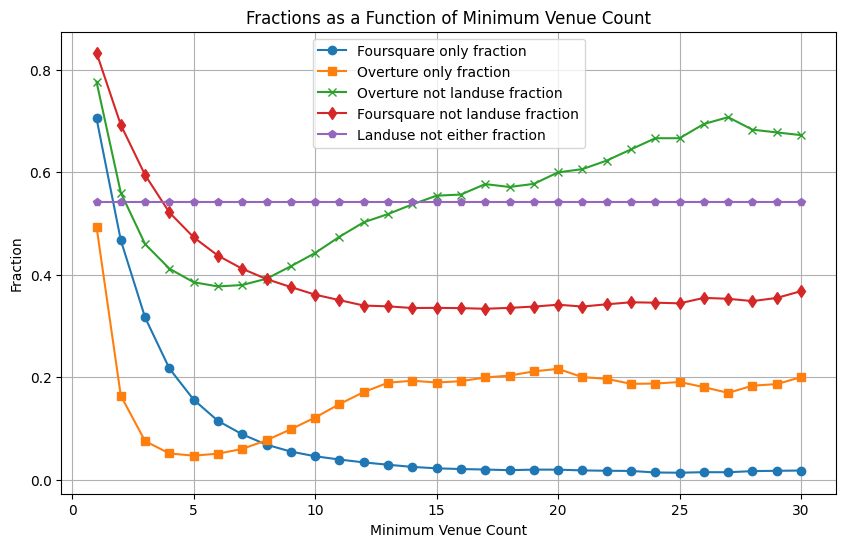

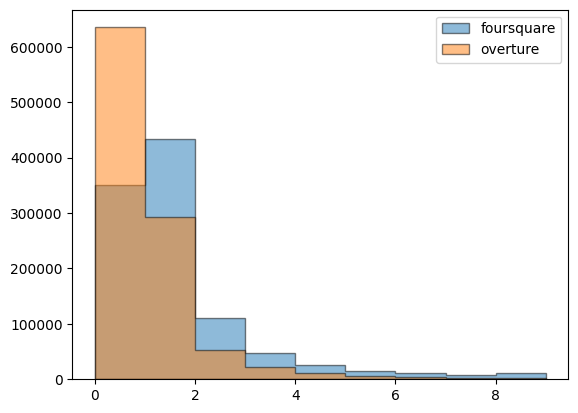

In [6]:

def plot_fractions(combined, max_min_venue_count):
    min_venue_counts = range(1, max_min_venue_count + 1)
    foursquare_only_fractions = []
    overture_only_fractions = []
    overture_not_landuse_fractions = []
    foursquare_not_landuse_fractions = []
    land_use_not_either_fractions = []

    for min_retail_venues in min_venue_counts:
        # Fraction for 'foursquare_count' but not in 'overture_count'
        fsq_only_fraction = (
            combined.filter(pl.col("foursquare_count") >= min_retail_venues)
            .filter(pl.col("overture_count") == 0)
            .height
            / combined.filter(pl.col("foursquare_count") >= min_retail_venues).height
        )
        foursquare_only_fractions.append(fsq_only_fraction)

        # Fraction for 'overture_count' but not in 'foursquare_count'
        overt_only_fraction = (
            combined.filter(pl.col("overture_count") >= min_retail_venues)
            .filter(pl.col("foursquare_count") == 0)
            .height
            / combined.filter(pl.col("overture_count") >= min_retail_venues).height
        )
        overture_only_fractions.append(overt_only_fraction)

        # Overture but not landuse
        overture_not_landuse = (
            combined.filter(pl.col("overture_count") >= min_retail_venues)
            .filter(pl.col("retail_landuse") == False)
            .height
            / combined.filter(pl.col("overture_count") >= min_retail_venues).height
        )
        overture_not_landuse_fractions.append(overture_not_landuse)

        # Foursquare but not landuse
        foursquare_not_landuse = (
            combined.filter(pl.col("foursquare_count") >= min_retail_venues)
            .filter(pl.col("retail_landuse") == False)
            .height
            / combined.filter(pl.col("foursquare_count") >= min_retail_venues).height
        )
        foursquare_not_landuse_fractions.append(foursquare_not_landuse)

        # Landuse but not either
        land_use_not_either = (
            combined.filter(pl.col("retail_landuse") == True)
            .filter((pl.col("foursquare_count") == 0) & (pl.col("overture_count") == 0))
            .height
            / combined.filter(pl.col("retail_landuse") == True).height
        )
        land_use_not_either_fractions.append(land_use_not_either)

    # Plot the results
    plt.figure(figsize=(10, 6))
    plt.plot(min_venue_counts, foursquare_only_fractions, label="Foursquare only fraction", marker="o")
    plt.plot(min_venue_counts, overture_only_fractions, label="Overture only fraction", marker="s")
    plt.plot(min_venue_counts, overture_not_landuse_fractions, label="Overture not landuse fraction", marker="x")
    plt.plot(min_venue_counts, foursquare_not_landuse_fractions, label="Foursquare not landuse fraction", marker="d")
    plt.plot(min_venue_counts, land_use_not_either_fractions, label="Landuse not either fraction", marker="p")
    plt.xlabel("Minimum Venue Count")
    plt.ylabel("Fraction")
    plt.title("Fractions as a Function of Minimum Venue Count")
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
plot_fractions(combined, 30)


overture_cells

#plot hist of retail_count (0,10)
plt.hist(combined['foursquare_count'], bins=range(0, 10), alpha=0.5, label='foursquare', histtype = 'stepfilled', edgecolor='black')
plt.hist(combined['overture_count'], bins=range(0, 10), alpha=0.5, label='overture', histtype = 'stepfilled', edgecolor='black')
plt.legend(loc='upper right')
plt.show()

## filter cells

In [7]:
min_retail_venues = 2
input_cells = combined.filter(
    (pl.col("foursquare_count") >= min_retail_venues) | (pl.col("retail_landuse") == True)
)

In [8]:
input_cells

h3_11,foursquare_count,retail_landuse,overture_count
str,u32,bool,u32
"""8b1972392d9afff""",2,false,0
"""8b19541758a9fff""",4,false,1
"""8b194659ad0bfff""",3,false,0
"""8b194e68e6d3fff""",2,false,0
"""8b195b4442d0fff""",12,true,7
…,…,…,…
"""8b1955d8e164fff""",0,true,0
"""8b1951076a15fff""",0,true,0
"""8b1909ad8ae4fff""",0,true,0


In [9]:
# Example usage
cells_with_network = ut.create_networks(input_cells)

In [10]:
cells_with_network

h3_11,network_number,trackNodes,foursquare_count,retail_landuse,overture_count,total_overture_count,total_foursquare_count
str,i64,i64,u32,bool,u32,u32,u32
"""8b195c3adc96fff""",1,168,1,true,0,74,166
"""8b195c3acac9fff""",1,168,4,true,1,74,166
"""8b195c3ac361fff""",1,168,11,true,0,74,166
"""8b195c3aca96fff""",1,168,1,true,0,74,166
"""8b195c3acacbfff""",1,168,2,true,3,74,166
…,…,…,…,…,…,…,…
"""8b194855a511fff""",33261,2,2,false,0,0,4
"""8b195d9a660bfff""",33262,2,8,false,5,5,10
"""8b195d9a6609fff""",33262,2,2,false,0,5,10


(array([    0., 74927., 22550., 15240., 12700., 10550.,  9162.,  7721.,
        13708.]),
 array([0., 1., 2., 3., 4., 5., 6., 7., 8., 9.]),
 [<matplotlib.patches.Polygon at 0x7fdf55e5b450>])

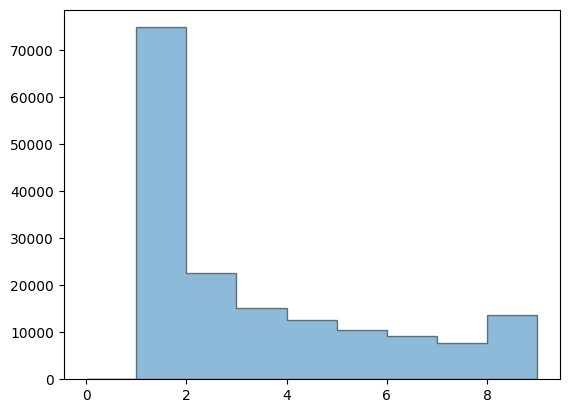

In [9]:
#hist trackNodes
plt.hist(cells_with_network['trackNodes'], bins=range(0, 10), alpha=0.5, label='trackNodes', histtype = 'stepfilled', edgecolor='black')

In [10]:
#how many are two or more
cells_with_network.filter(pl.col('trackNodes') >= 2).height

381756

In [13]:
#rename overture_count to total_retail_count

df = cells_with_network

#island rmeoval
#keep only the networks with more than 10 retail venues or more than 1 track node 
#We prune the exhaustive set of retail cen-
#tres to include only those with at least two hexagon units and at least ten overall retail unit points contained
#within them, a threshold used by Pavlis et al. (2018) and based on UK retail planning policy 18 . 
df = df.filter((df['total_foursquare_count'] >= 10) | (df['trackNodes'] >= 2)).filter(df['total_foursquare_count'] >= 15).sort("network_number")

#"In England and Wales, agglomerations with less than
#fifteen VOA retail points and ten OSM retail points are removed from the set, while for Scotland and Northern
#Ireland the condition is based on ten OSM points."""
#from https://www.ons.gov.uk/peoplepopulationandcommunity/populationandmigration/populationestimates/articles/highstreetsingreatbritain/march2020
#Spatial clustering has been implemented using the data clustering algorithm DBSCAN (Density-based spatial clustering of applications with noise). Candidate retail clusters required a minimum of 15 retail address point geometries within 15 buildings and a maximum of 150 metres between the address geometries in the cluster.


ut.to_parquet(df, 'uk_overture_retail_networks_test')

In [11]:
cells_with_network

h3_11,network_number,trackNodes,foursquare_count,retail_landuse,overture_count,total_overture_count,total_foursquare_count
str,i64,i64,u32,bool,u32,u32,u32
"""8b195cd96d62fff""",1,4,1,true,0,1,4
"""8b195cd96d75fff""",1,4,2,true,1,1,4
"""8b195cd96d71fff""",1,4,1,true,0,1,4
"""8b195cd96d66fff""",1,4,0,true,0,1,4
"""8b1951a41b56fff""",2,2,4,false,0,0,7
…,…,…,…,…,…,…,…
"""8b195a140819fff""",33261,2,4,false,1,1,6
"""8b195c059b71fff""",33262,2,2,false,0,0,5
"""8b195c059b62fff""",33262,2,3,false,0,0,5


In [73]:


# # Assuming h3_with_networks is the DataFrame you're working with
# data = df

# # Step 1: Build adjacency map using H3 neighbors
# h3_indices = data["h3_address"].to_list()
# networks = data["network_number"].to_list()

# # Build neighbors_map using h3.k_ring
# neighbors_map = {
#     (h, n): set(h3.grid_ring(h, 1)) for h, n in zip(h3_indices, networks)
# }

# #save to geoparquet
# # Convert the neighbors_map dictionary to a DataFrame
# neighbors_df = pl.DataFrame(
#     {
#         "h3_address": [h3_address for h3_address, _ in neighbors_map.keys()],
#         "network_number": [network for _, network in neighbors_map.keys()],
#         "neighbors": [neighbors for neighbors in neighbors_map.values()],
#     }
# )

# # Step 3: Create a DataFrame with the neighbors and network number
# rows = []
# for (h, n), neighbors in neighbors_map.items():
#     for neighbor in neighbors:
#         rows.append({"h3_address": neighbor, "network_number": n})

# # Step 4: Create the DataFrame
# neighbors_df = pd.DataFrame(rows)

# # Display the resulting DataFrame
# print(neighbors_df)

# to_parquet(neighbors_df, 'neighbors')



# # Combine entries with the same network number
# combined_neighbors = defaultdict(set)
# for (h3_address, network), neighbors in neighbors_map.items():
#     if network == 76:
#         print('chorlton1', neighbors)
#     if network == 163:
#         print('chorlton2', neighbors)
#     combined_neighbors[network].update(neighbors)


# #save the combined neighbors to geoparquet
# # Convert the combined_neighbors dictionary to a DataFrame
# combined_neighbors_df = pl.DataFrame(
#     {
#         "network_number": [network for network, _ in combined_neighbors.items()],
#         "neighbors": [neighbors for _, neighbors in combined_neighbors.items()],
#     }






# # Function to find overlapping networks and add the overlapping neighbors
# def find_overlapping_networks_and_add_neighbors(combined_neighbors):
#     overlapping_pairs = []
#     new_rows = []  # To hold new rows to be added to the table
    
#     # Get all pairs of networks
#     for (network1, neighbors1), (network2, neighbors2) in combinations(combined_neighbors.items(), 2):
#         # Check if there's any overlap in their neighbor sets
#         overlap = neighbors1 & neighbors2  # Non-empty intersection
#         if overlap:
#             print(f"Network {network1} and Network {network2} overlap with {len(overlap)} hexes")
#             overlapping_pairs.append((network1, network2))
            
#             # Add the overlapping neighbor hexes to the new network
#             for hex in overlap:
#                 # Check if the hex is not already in the original data for either network
#                 if hex not in data['h3_address'].to_list():
#                     new_rows.append({
#                         'h3_address': hex,
#                         'network_number': network1,
#                         'retail_count': 0,  # Default retail count for new hexes, can be updated later
#                         'total_retail_count': 0  # This will be recalculated later
#                     })
    
#     return overlapping_pairs, new_rows

# # Find overlapping pairs of networks and add new rows
# overlapping_pairs, new_rows = find_overlapping_networks_and_add_neighbors(combined_neighbors)

# # Create a dictionary that maps the old network number to the merged network
# network_mapping = {}
# for network1, network2 in overlapping_pairs:
#     # Assign the same merged network number to both networks
#     network_mapping[network1] = network2
#     network_mapping[network2] = network2  # Ensure the second network also maps to the same merged value

# # Convert DataFrame to Pandas
# data = data.to_pandas()
# # Add new rows for overlapping hexes
# new_df = pd.DataFrame(new_rows)
# data = pd.concat([data, new_df], ignore_index=True)

# print(overlapping_pairs)
# # Apply the mapping to the network_number column
# data['network_number'] = data['network_number'].map(network_mapping).fillna(data['network_number'])



# # Recalculate the total_retail_count by summing retail_count per merged network
# data['total_retail_count'] = data.groupby('network_number')['retail_count'].transform('sum')

# # Convert back to Polars DataFrame
# data = pl.DataFrame(data)

# # Show the updated table
# print(data)

# h3_with_networks = data


In [ ]:
df = ut.to_geoframe(df)
dissolved = (
    df
    .dissolve(by='network_number', as_index=False)
    .reset_index(drop=True)
)

dissolved['geometry'] = dissolved['geometry'].apply(lambda geom: ut.fill_holes(geom))

# Final GeoDataFrame with dissolved unique polygons
dissolved_unique_gdf = gpd.GeoDataFrame(dissolved, geometry='geometry', crs='EPSG:27700')
dissolved_unique_gdf.to_parquet('data/output_files/uk_overture_retail_networks_dissolved.parquet')

Series([], dtype: int64)
5328
5328
